In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total missing values: 0


In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total missing values: 0


In [5]:
display(df.describe())

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [6]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date column data type:", df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())

Date column data type: datetime64[us]
Invalid dates: 0


In [7]:
numeric_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

print("MEAN")
display(df[numeric_cols].mean())

print("MEDIAN")
display(df[numeric_cols].median())

print("MODE")
display(df[numeric_cols].mode().iloc[0])

print("STANDARD DEVIATION")
display(df[numeric_cols].std())

MEAN


Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN


Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE


Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

STANDARD DEVIATION


Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

Date
2023-01-01    35450
2023-02-01    44060
2023-03-01    28990
2023-04-01    33870
2023-05-01    53150
2023-06-01    36715
2023-07-01    35465
2023-08-01    36960
2023-09-01    23620
2023-10-01    46580
2023-11-01    34920
2023-12-01    44690
2024-01-01     1530
Freq: MS, Name: Total Amount, dtype: int64

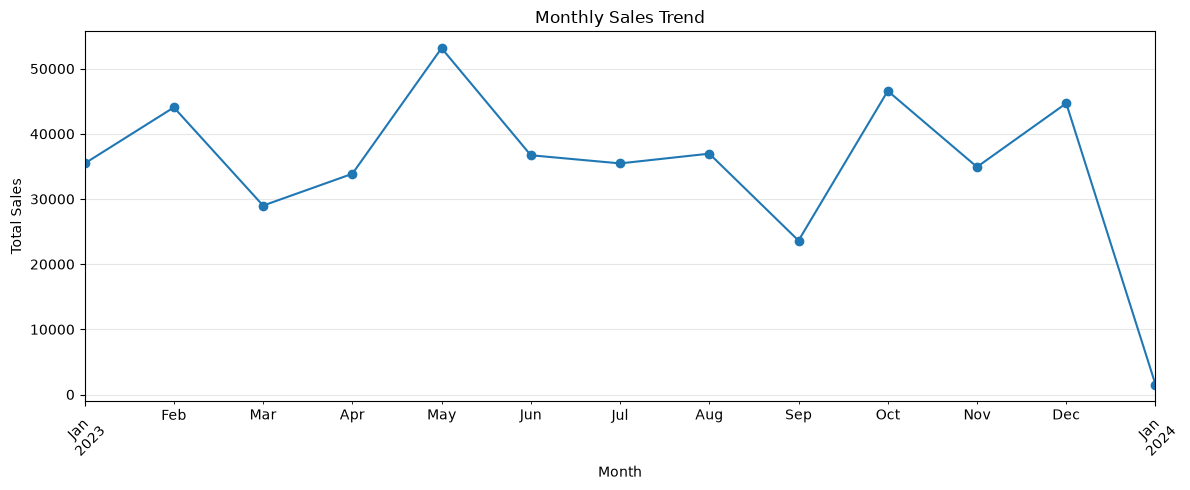

In [ ]:
monthly_sales = (
    df.set_index("Date")["Total Amount"]
      .resample("MS")
      .sum()
)

display(monthly_sales)

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Sales Trend — Observations

1. **Highest sales:** May recorded the highest monthly sales in the observed period.
2. **Lowest sales:** January 2024 recorded the lowest sales. This month may contain fewer days of data than other months, so the result should be interpreted cautiously.
3. **Overall trend:** Monthly sales fluctuated throughout the period, indicating variations in sales performance rather than a consistent increase or decrease.

**Business insight:** The business can investigate the factors behind May's strong sales and examine monthly fluctuations to identify opportunities for more consistent revenue.

Date
2023-01-01    108500
2023-04-01    123735
2023-07-01     96045
2023-10-01    126190
2024-01-01      1530
Freq: QS-JAN, Name: Total Amount, dtype: int64

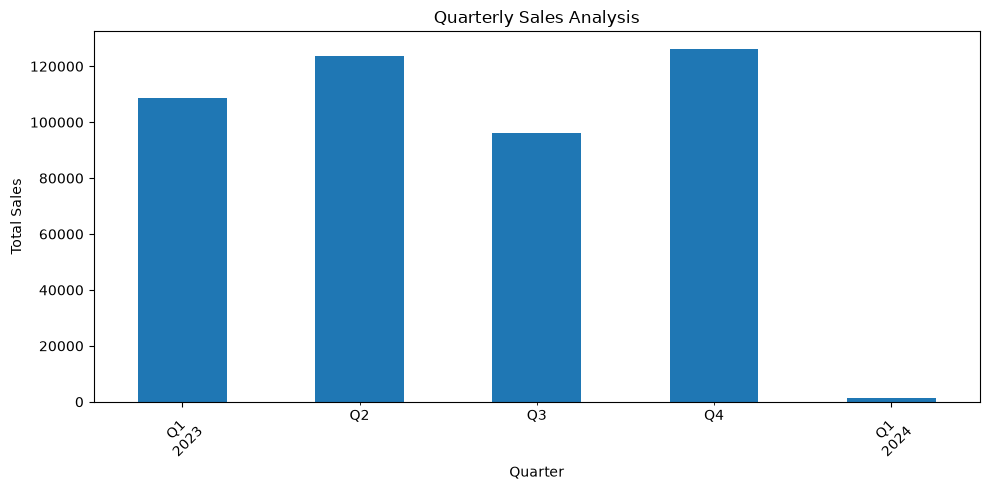

In [9]:
quarterly_sales = (
    df.set_index("Date")["Total Amount"]
      .resample("QS")
      .sum()
)

display(quarterly_sales)

plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind="bar")

plt.title("Quarterly Sales Analysis")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Quarterly Sales Analysis — Observations

1. **Highest sales:** Q4 2023 recorded the highest quarterly sales in the observed period.
2. **Lowest sales:** Q3 2023 recorded the lowest quarterly sales.
3. **Business insight:** The difference between Q3 and Q4 may indicate seasonal demand or changes in customer purchasing patterns. Further analysis is needed to identify the cause.

**Recommendation:** The business should investigate which product categories contributed most to Q4 sales and consider whether successful promotions or seasonal campaigns could be repeated.

In [10]:
monthly_transactions = (
    df.set_index("Date")["Transaction ID"]
      .resample("MS")
      .count()
)

display(monthly_transactions)

Date
2023-01-01     76
2023-02-01     85
2023-03-01     73
2023-04-01     86
2023-05-01    105
2023-06-01     77
2023-07-01     72
2023-08-01     94
2023-09-01     65
2023-10-01     96
2023-11-01     78
2023-12-01     91
2024-01-01      2
Freq: MS, Name: Transaction ID, dtype: int64

Customer transactions by gender:


Gender
Female    510
Male      490
Name: count, dtype: int64

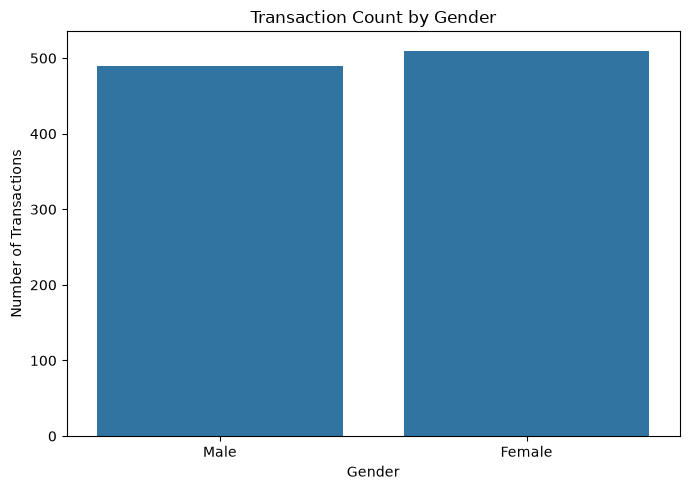

In [11]:
gender_counts = df["Gender"].value_counts()

print("Customer transactions by gender:")
display(gender_counts)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender")

plt.title("Transaction Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

### Data Coverage Observation

The dataset contains 1,000 transactions. Monthly transaction counts vary throughout 2023, ranging from 65 to 105 records. May 2023 has the highest number of transactions, with 105 records.

January 2024 contains only two transactions, suggesting that the month is incompletely represented in the dataset. Therefore, its monthly sales total should not be directly compared with complete months when evaluating business performance.

**Conclusion:** Monthly sales comparisons should consider the number of transactions and the period covered by the data.

Transaction count by age group:


Age Group
18–25    169
26–35    205
36–45    202
46–55    229
56–65    195
Name: count, dtype: int64

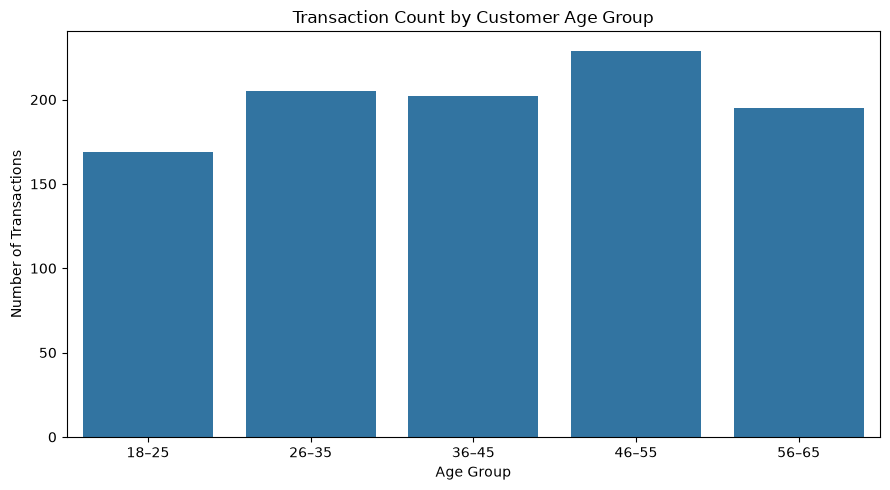

In [24]:
bins = [17, 25, 35, 45, 55, 65]
labels = ["18–25", "26–35", "36–45", "46–55", "56–65"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

age_counts = (
    df["Age Group"]
    .value_counts()
    .sort_index()
)

print("Transaction count by age group:")
display(age_counts)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Age Group",
    order=labels
)

plt.title("Transaction Count by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

Total sales by gender:


Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

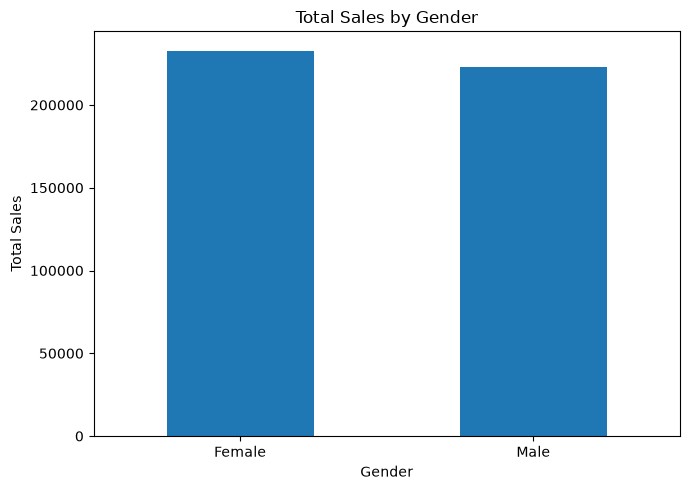

In [15]:
gender_sales = (
    df.groupby("Gender", observed=True)["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

print("Total sales by gender:")
display(gender_sales)

gender_sales.plot(kind="bar", figsize=(7, 5))

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Customer Demographics — Observations

1. **Gender distribution:** Female customers account for more transaction records than male customers in the dataset.
2. **Age group:** Customers aged 46–55 represent the largest age group by transaction count.
3. **Revenue by gender:** Female customers contribute more total sales revenue than male customers.
4. **Business insight:** The business could investigate which products and categories are popular among female customers and customers aged 46–55.

**Recommendation:** Use these findings as a starting point for targeted marketing. Further analysis of category preferences, average spending, and unique customers would help validate these opportunities.

In [16]:
category_summary = (
    df.groupby("Product Category")
      .agg(
          Transactions=("Transaction ID", "count"),
          Units_Sold=("Quantity", "sum"),
          Total_Revenue=("Total Amount", "sum"),
          Average_Transaction_Value=("Total Amount", "mean")
      )
      .sort_values("Total_Revenue", ascending=False)
)

display(category_summary.round(2))

,Transactions,Units_Sold,Total_Revenue,Average_Transaction_Value
Product Category,,,,
Electronics,342,849,156905,458.79
Clothing,351,894,155580,443.25
Beauty,307,771,143515,467.48


,Transactions,Units_Sold,Total_Revenue,Average_Transaction_Value,Revenue_Percentage
Product Category,,,,,
Electronics,342,849,156905,458.79,34.41
Clothing,351,894,155580,443.25,34.12
Beauty,307,771,143515,467.48,31.47


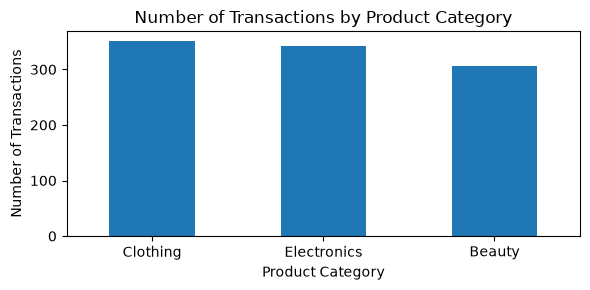

In [26]:
category_summary["Revenue_Percentage"] = (
    category_summary["Total_Revenue"]
    / category_summary["Total_Revenue"].sum()
    * 100
)

display(category_summary.round(2))
category_counts = df["Product Category"].value_counts()

plt.figure(figsize=(6, 3))
category_counts.plot(kind="bar")

plt.title("Number of Transactions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

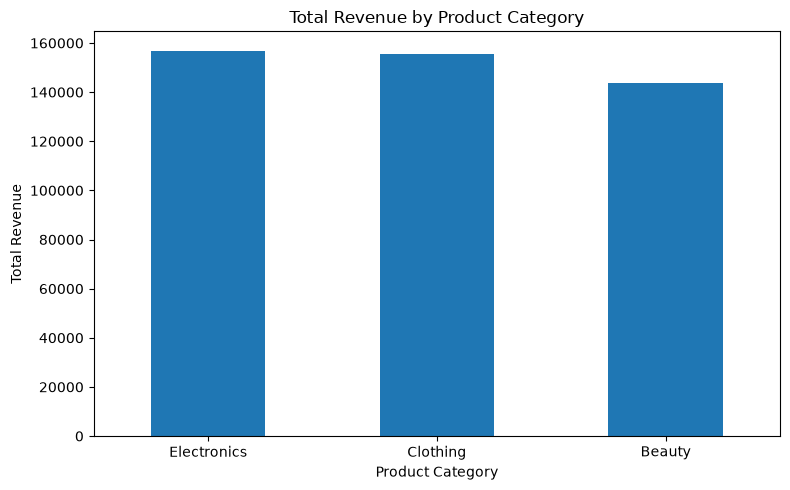

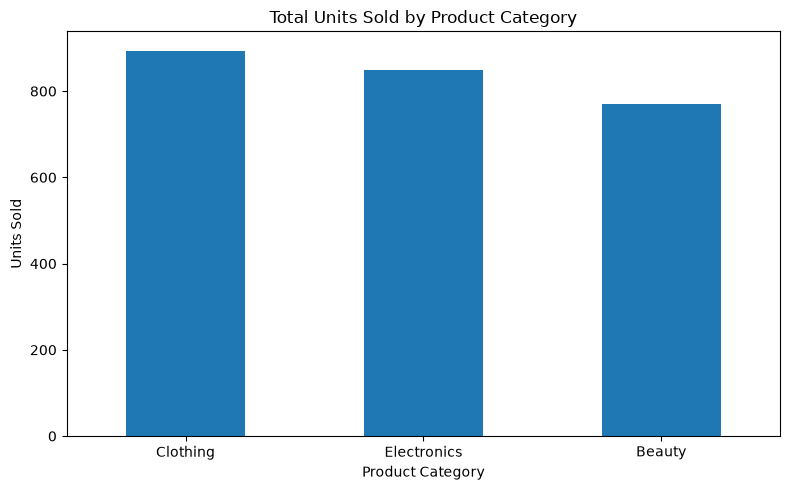

In [ ]:
revenue_by_category = (
    df.groupby("Product Category")["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(6,3))
revenue_by_category.plot(kind="bar")

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
quantity_by_category = (
    df.groupby("Product Category")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(6, 3))
quantity_by_category.plot(kind="bar")

plt.title("Total Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Product Category and Revenue Analysis — Observations

1. **Highest revenue category:** Electronics contributes 34.41% of total revenue, making it the leading category by revenue.
2. **Highest transaction count:** Clothing has the greatest number of transactions.
3. **Highest quantity sold:** Clothing also records the highest total units sold.
4. **Business insight:** Clothing drives purchase volume, while Electronics generates the largest revenue contribution. This suggests that transaction volume and revenue should be evaluated separately.

**Recommendations:**
- Maintain sufficient inventory for Clothing because of its high sales volume.
- Investigate the pricing, product mix, and customer preferences contributing to Electronics revenue.
- Compare average transaction values and profit margins across categories before making inventory or marketing decisions.

**Data limitation:** The dataset contains product categories rather than individual product names, so individual product rankings cannot be calculated.

Correlation Matrix:


,Age,Quantity,Price per Unit,Total Amount
Age,1.00,-0.02,-0.04,-0.06
Quantity,-0.02,1.00,0.02,0.37
Price per Unit,-0.04,0.02,1.00,0.85
Total Amount,-0.06,0.37,0.85,1.00


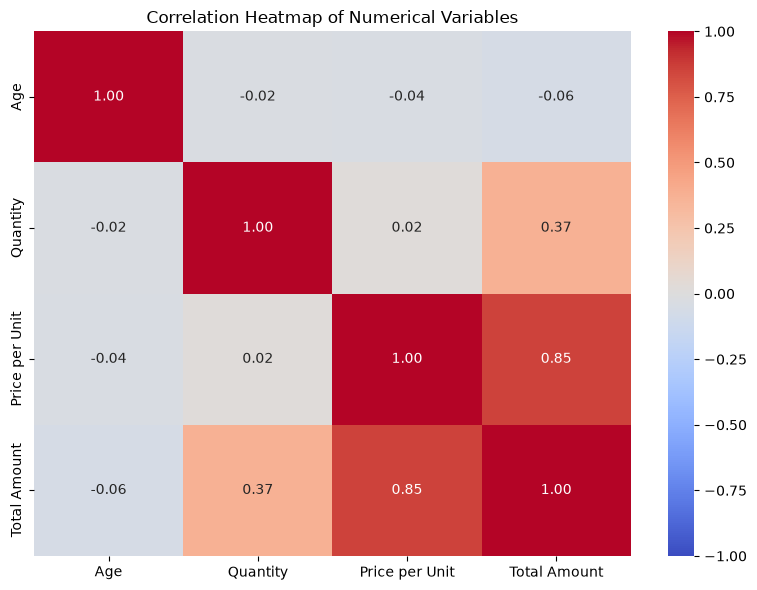

In [21]:
numeric_cols = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

correlation_matrix = df[numeric_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

Product Category,Beauty,Clothing,Electronics
Age Group,,,
18–25,521.33,519.80,461.38
26–35,466.27,540.20,426.02
36–45,526.02,388.82,471.04
46–55,489.01,401.12,432.74
56–65,324.91,392.70,507.27


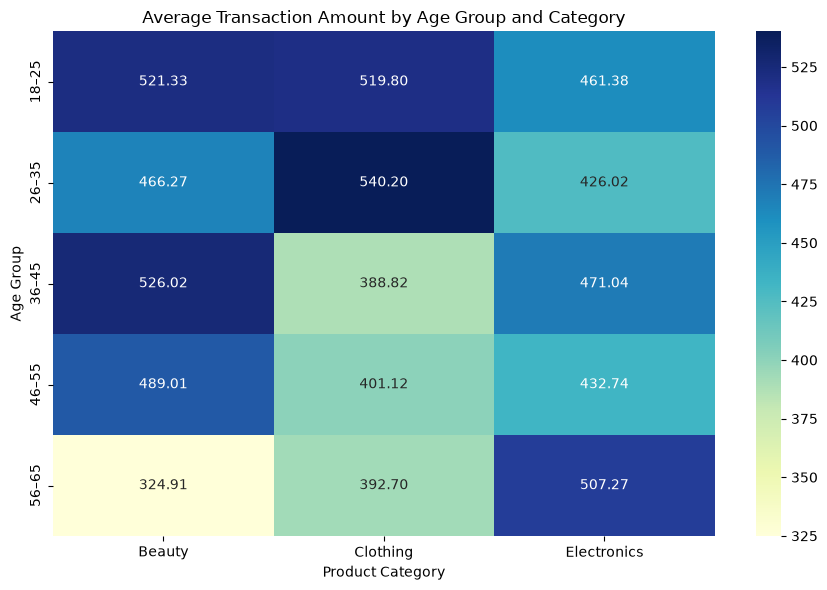

In [22]:
age_category_spending = df.pivot_table(
    index="Age Group",
    columns="Product Category",
    values="Total Amount",
    aggfunc="mean",
    observed=False
)

display(age_category_spending.round(2))

plt.figure(figsize=(9, 6))

sns.heatmap(
    age_category_spending,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Transaction Amount by Age Group and Category")
plt.xlabel("Product Category")
plt.ylabel("Age Group")
plt.tight_layout()
plt.show()

## Business Recommendations

Based on the exploratory analysis, the following actions are recommended:

1. **Improve inventory planning:** Clothing has the highest transaction count and units sold. The retailer should monitor demand and maintain suitable inventory levels to reduce stockouts.

2. **Optimize Electronics sales:** Electronics contributes 34.41% of total revenue and leads the categories by revenue. The retailer should investigate its pricing, product mix, and customer preferences to identify opportunities for growth.

3. **Plan seasonal campaigns:** Q4 2023 recorded the highest quarterly sales, while Q3 2023 recorded the lowest. The business should investigate possible seasonal factors and test targeted campaigns before the next peak period.

4. **Use customer demographics carefully:** Female customers account for more transaction records and higher total sales, while ages 46–55 have the most transactions. The retailer could examine category preferences for these groups before designing targeted promotions.

5. **Use data-driven decisions:** Correlation analysis shows a strong positive relationship between unit price and total transaction amount (+0.85), and a moderate positive relationship between quantity and total amount (+0.37). These relationships should be interpreted in the context of how transaction totals are calculated.

6. **Improve analysis coverage:** January 2024 contains only two transactions. Additional data covering complete months would support more reliable month-to-month comparisons.

## Conclusion

This exploratory data analysis examined retail sales trends, customer demographics, product category performance, and relationships between numerical variables. The findings indicate that sales volume and revenue leadership differ by category, and that data coverage must be considered when interpreting trends.

The analysis provides a starting point for better inventory planning, marketing decisions, and further investigation of customer purchasing behavior.

### Additional Visualization — Key Findings

The heatmap shows differences in average transaction amounts across age groups and product categories. Customers aged 36–45 have the highest average transaction amount for Beauty (526.02), while customers aged 26–35 lead in Clothing (540.20). For Electronics, customers aged 56–65 have the highest average transaction amount (507.27).

**Business insight:** The retailer could investigate age-group preferences and test category-specific promotions. These results describe average transaction amounts and do not necessarily represent total revenue or profitability.

## Conclusion

In this project, I explored a retail sales dataset containing 1,000 transactions and 9 columns using Python, Pandas, Matplotlib, and Seaborn.

I checked the dataset for missing values, duplicate rows, and invalid dates. I then analyzed monthly and quarterly sales, customer demographics, product categories, and correlations between numerical variables.

My analysis showed that May 2023 had the highest number of monthly transactions, while January 2024 had only two transactions, so its sales should be interpreted carefully. Q4 2023 had the highest quarterly sales in my chart.

I also found that Clothing had the most transactions and units sold, while Electronics generated the highest revenue share at 34.41%. The additional heatmap showed that average transaction amounts differed across age groups and product categories.

Based on these findings, I would recommend maintaining enough Clothing inventory, investigating what drives Electronics revenue, and using complete monthly data for more reliable comparisons. Overall, this project helped me practise data cleaning, exploratory data analysis, visualization, and interpreting results for business decisions.